<a href="https://colab.research.google.com/github/fortiz11/Network-intrusion-detection/blob/main/network_Intrusion_detection_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#Library Imports


import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [5]:



#Imports our test/train data
test_df= pd.read_csv("UNSW_NB15_testing-set.csv")
train_df=pd.read_csv("UNSW_NB15_training-set.csv")

#Prints data dimensions
print("Test data" , test_df.shape)
print("Training data" ,train_df.shape)

train_df.head()

#Displays column names and nonnull counts
print(train_df.columns.tolist())
train_df.info()

#Check for missing values
print(train_df.isnull().sum())



Test data (82332, 45)
Training data (175341, 45)
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              17534

In [6]:
# Check the distribution of normal and attack traffic
print(train_df["label"].value_counts())

#Check for duplicate rows
print("Duplicate rows", train_df.drop(columns=["id"]).duplicated().sum())

#check for infinite values

numeric_cols = train_df.select_dtypes(include="number")
print(np.isinf(numeric_cols).sum())

label
1    119341
0     56000
Name: count, dtype: int64
Duplicate rows 67601
id                   0
dur                  0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
lab

In [7]:

# Identify duplicate records, excluding the ID column
duplicates = train_df.drop(columns=["id"]).duplicated()

# Count duplicates by traffic type
print(train_df.loc[duplicates, "label"].value_counts())


label
1    63491
0     4110
Name: count, dtype: int64


In [8]:

# Create a copy of the training data without duplicates
#Creating 2 different sets because we have a alot of duplicate
# malicious traffic.
train_clean = train_df.drop_duplicates(
    subset=train_df.columns.drop("id")
).copy()

# Check the new dataset size
print("Original training data:", train_df.shape)
print("Cleaned training data:", train_clean.shape)

# Check the new class distribution
print(train_clean["label"].value_counts())


Original training data: (175341, 45)
Cleaned training data: (107740, 45)
label
1    55850
0    51890
Name: count, dtype: int64


In [9]:
#Separate input features form target labels

X_train = train_clean.drop(columns=["id", "attack_cat", "label"])
y_train = train_clean["label"]

X_test = test_df.drop(columns=["id", "attack_cat", "label"])
y_test= test_df["label"]

print("Training features", X_train.shape)
print("Training labels", y_train.shape)
print("Testing features", X_test.shape)
print("Testing labels", y_test.shape)


Training features (107740, 42)
Training labels (107740,)
Testing features (82332, 42)
Testing labels (82332,)


In [10]:
#See what data is categorical and which is numerical

categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

numerical_cols= X_train.select_dtypes(include="number").columns.tolist()

print("Categorical data", categorical_cols)
print("Number of categorical features", len(categorical_cols))

Categorical data ['proto', 'service', 'state']
Number of categorical features 3


In [11]:
#One-Hot encoding of the data

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

#encodes the training data
X_train_cat = encoder.fit_transform(X_train[categorical_cols])

#encodes the test data
X_test_cat= encoder.transform(X_test[categorical_cols])

print("Encoded training features:", X_train_cat.shape)
print("Encoded testing features:", X_test_cat.shape)

Encoded training features: (107740, 155)
Encoded testing features: (82332, 155)


In [12]:
#Combine numerical and encoded features

X_train_final =np.hstack([X_train[numerical_cols].to_numpy(), X_train_cat])
X_test_final = np.hstack([X_test[numerical_cols].to_numpy(), X_test_cat])

print("Final Training features", X_train_final.shape)
print("Final Testing features", X_test_final.shape)

Final Training features (107740, 194)
Final Testing features (82332, 194)


In [13]:
#Scale numerical columns

scaler = StandardScaler()

#Scale using the training data
X_train_num_scaled = scaler.fit_transform(X_train[numerical_cols])

X_test_num_scaled = scaler.transform(X_test[numerical_cols])

#Only scaling the 39 numerical columns
print("Scaled training data", X_train_num_scaled.shape)
print("Scaled test data", X_test_num_scaled.shape)

Scaled training data (107740, 39)
Scaled test data (82332, 39)


In [14]:
#Combine scaled data with the encoded data

X_train_scaled= np.hstack([X_train_num_scaled, X_train_cat])

X_test_scaled= np.hstack([X_test_num_scaled, X_test_cat])

print("Scaled training features:", X_train_scaled.shape)
print("Scaled testing features:", X_test_scaled.shape)

Scaled training features: (107740, 194)
Scaled testing features: (82332, 194)


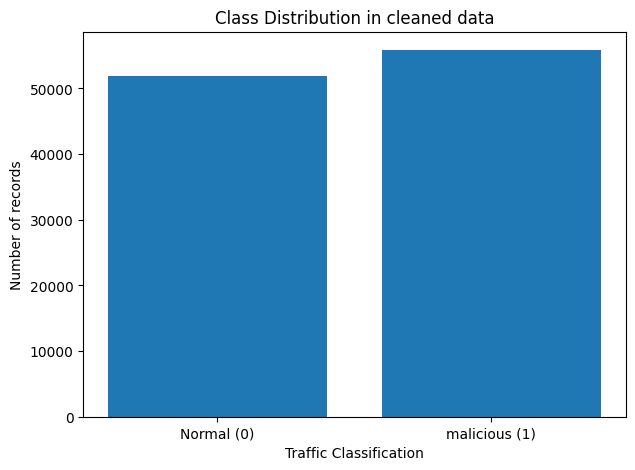

In [15]:
class_counts= y_train.value_counts().sort_index()

plt.figure(figsize=(7,5))
plt.bar(["Normal (0)", "malicious (1)"], class_counts.values)

plt.title("Class Distribution in cleaned data")
plt.xlabel("Traffic Classification")
plt.ylabel("Number of records")

plt.show()

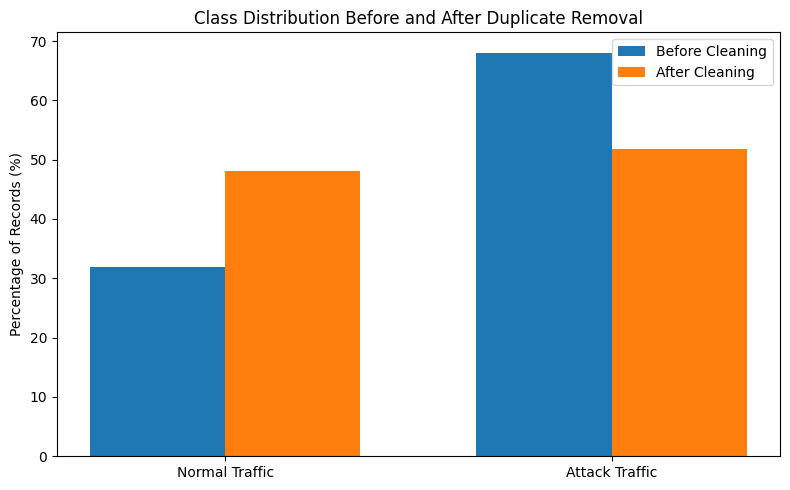

In [16]:

# Graph 2: Class distribution before and after cleaning

before = train_df["label"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
after = train_clean["label"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

labels = ["Normal Traffic", "Attack Traffic"]
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, before.values, width, label="Before Cleaning")
plt.bar(x + width/2, after.values, width, label="After Cleaning")

plt.xticks(x, labels)
plt.ylabel("Percentage of Records (%)")
plt.title("Class Distribution Before and After Duplicate Removal")
plt.legend()
plt.tight_layout()
plt.show()

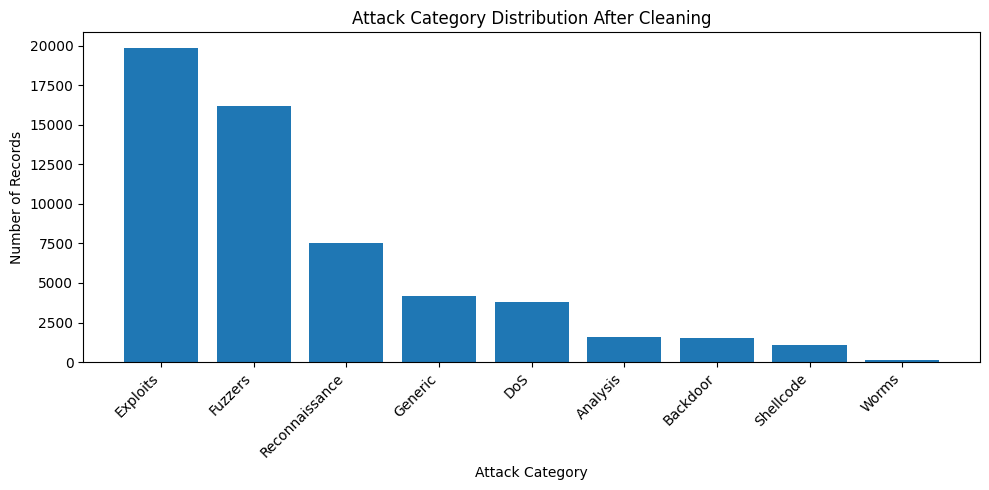

In [17]:

# Graph 3: Distribution of attack categories after cleaning

attack_counts = train_clean[
    train_clean["label"] == 1
]["attack_cat"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(attack_counts.index, attack_counts.values)

plt.title("Attack Category Distribution After Cleaning")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
